# Predicting Student Dropout and Academic Success

**IT5022 Fundamentals of Machine Learning · Group Assignment (group of 2)**

| Member | Registration | Owns, as set out in the project plan |
|---|---|---|
| Kusal Dissanayake | MS26929064 | Random Forest and the decision trees behind it; PCA |
| Lahiru Sandeepa | MS26929378 | Logistic Regression; scaling; SMOTE, the threshold sweep and ROC/PR analysis; |



---

### Problem statement
Student dropout is costly for universities and students alike. Using information available at enrolment and after the
first two semesters, we predict whether a student will **Graduate**, remain **Enrolled**, or **Drop out** — a
**supervised, 3-class classification** problem that can power an early-warning / student-support system.

### Dataset
- **Name:** Predict Students' Dropout and Academic Success
- **Source:** UCI Machine Learning Repository, dataset **#697** — https://archive.ics.uci.edu/dataset/697 (DOI 10.24432/C5MC89)
- **Size:** 4,424 students · 36 features · target `{Dropout, Enrolled, Graduate}`
- **Features:** demographics (marital status, nationality, gender, age), socio-economic context (parents'
  qualifications/occupations, tuition fees up to date, scholarship holder, debtor), academic background (application
  mode, previous/admission grade) and **curricular-unit performance in semesters 1 & 2*

## 1. Imports

In [1]:
# Core libraries (same stack used across the IT5022 lab notebooks)
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     GridSearchCV, cross_val_score, cross_validate)
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             matthews_corrcoef, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, roc_curve,
                             precision_recall_curve, auc)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 60)
print("Imports ready.")

Imports ready.


## 2. Data Loading

In [2]:
# Load UCI dataset #697 (primary: ucimlrepo package; fallback: local CSV saved by notebook 01)
def load_students():
    try:
        from ucimlrepo import fetch_ucirepo
        ds = fetch_ucirepo(id=697)
        X = ds.data.features.copy()
        y_raw = ds.data.targets.copy()
        df = pd.concat([X, y_raw], axis=1)
        print("Loaded from UCI repository (id=697).")
    except Exception as e:
        print("ucimlrepo unavailable, using local CSV:", e)
        df = pd.read_csv("data/students_dropout.csv")
    return df

df = load_students()
print("Shape:", df.shape)
df.head()

Loaded from UCI repository (id=697).
Shape: (4424, 37)


,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


Shape: (4424, 37)
Total missing cells: 0 | Duplicate rows: 0


,Count,Percentage %
Target,,
Graduate,2209,49.9
Dropout,1421,32.1
Enrolled,794,17.9


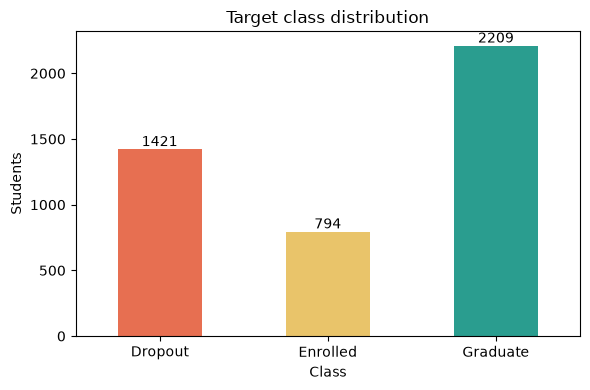

In [3]:
print("Shape:", df.shape)
print("Total missing cells:", int(df.isna().sum().sum()), "| Duplicate rows:", int(df.duplicated().sum()))
counts = df["Target"].value_counts()
display(pd.DataFrame({"Count": counts,
                      "Percentage %": df["Target"].value_counts(normalize=True).mul(100).round(1)}))
fig, ax = plt.subplots(figsize=(6,4))
counts.loc[["Dropout","Enrolled","Graduate"]].plot(kind="bar",
        color=["#e76f51","#e9c46a","#2a9d8f"], ax=ax)
ax.set_title("Target class distribution"); ax.set_xlabel("Class"); ax.set_ylabel("Students")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
plt.tight_layout(); plt.show()

## 3. Preprocessing & Feature Screening

The raw table becomes a matrix both models can use. Everything learned from data (encoder
levels, scaler means, PCA directions, screening scores) is learned from the training split
only and then applied unchanged to the test split, the rule Labs 04 and 05 set out.

### 3.1 Column names and column groups · *Lahiru, Kusal*

Two columns are renamed. The source misspells the nationality column as `Nacionality`, and
it codes `Gender` as 1 = male, 0 = female, so a column called `Gender` does not say which
value is 1; named `Male`, it reads correctly wherever it appears.

The 36 features then fall into three groups. Nine are national registry codes stored as
integers: `Course` 9254 is not "more" than `Course` 171, so these are categories with no
ordering. Eight are already 0/1 flags, and nineteen are genuine numbers or counts.

In [4]:
# fix the misspelt column and name the 0/1 gender flag after its value of 1
df = df.rename(columns={"Nacionality": "Nationality", "Gender": "Male"})

TARGET = "Target"
NOMINAL = ["Marital Status", "Application mode", "Course", "Previous qualification",
           "Nationality", "Mother's qualification", "Father's qualification",
           "Mother's occupation", "Father's occupation"]
BINARY = ["Daytime/evening attendance", "Displaced", "Educational special needs", "Debtor",
          "Tuition fees up to date", "Male", "Scholarship holder", "International"]
CONTINUOUS = (["Application order", "Previous qualification (grade)", "Admission grade",
               "Age at enrollment"]
              + [f"Curricular units {sem} sem ({kind})"
                 for sem in ("1st", "2nd")
                 for kind in ("credited", "enrolled", "evaluations", "approved", "grade",
                              "without evaluations")]
              + ["Unemployment rate", "Inflation rate", "GDP"])

# every feature belongs to exactly one group
assert len(NOMINAL + BINARY + CONTINUOUS) == 36
assert set(NOMINAL + BINARY + CONTINUOUS + [TARGET]) == set(df.columns)
print(f"nominal codes: {len(NOMINAL)} | binary flags: {len(BINARY)} | continuous: {len(CONTINUOUS)}")

df[NOMINAL].nunique().sort_values(ascending=False).rename("distinct codes").to_frame()

nominal codes: 9 | binary flags: 8 | continuous: 19


,distinct codes
Father's occupation,46
Father's qualification,34
Mother's occupation,32
Mother's qualification,29
Nationality,21
Application mode,18
Course,17
Previous qualification,17
Marital Status,6


### 3.2 Removing a redundant column · *Lahiru, Kusal*

`International` is not separate information: it is exactly "the nationality code is not 1
(Portuguese)". Keeping both adds a column and nothing else, so `International` is dropped.

In [5]:
is_foreign = (df["Nationality"] != 1).astype(int)
print("International == (Nationality != 1) for every row:", bool((df["International"] == is_foreign).all()))

df = df.drop(columns=["International"])
BINARY.remove("International")
print("features remaining:", df.shape[1] - 1)

International == (Nationality != 1) for every row: True
features remaining: 35


### 3.3 Four engineered features · *Lahiru, Kusal*

| feature | definition | why |
|---|---|---|
| `approval_rate_1st` | units approved ÷ units enrolled, 1st semester | 4 of 6 passed is not the same as 4 of 12 |
| `approval_rate_2nd` | the same for the 2nd semester | |
| `grade_trend` | 2nd semester grade − 1st semester grade | a falling and a recovering student can share an average |
| `total_approved` | units approved across both semesters | overall progress in one number |

Each is computed from a single row, so none can leak information between students, and they
are added before the split. A student enrolled in no units gets an approval rate of 0 rather
than a division by zero; these students are among the most at risk, so they are kept.

In [6]:
def approval_rate(approved, enrolled):
    # no units enrolled gives 0 instead of a division by zero
    return approved.div(enrolled.where(enrolled > 0)).fillna(0.0)

df["approval_rate_1st"] = approval_rate(df["Curricular units 1st sem (approved)"],
                                        df["Curricular units 1st sem (enrolled)"])
df["approval_rate_2nd"] = approval_rate(df["Curricular units 2nd sem (approved)"],
                                        df["Curricular units 2nd sem (enrolled)"])
df["grade_trend"] = df["Curricular units 2nd sem (grade)"] - df["Curricular units 1st sem (grade)"]
df["total_approved"] = (df["Curricular units 1st sem (approved)"]
                        + df["Curricular units 2nd sem (approved)"])

ENGINEERED = ["approval_rate_1st", "approval_rate_2nd", "grade_trend", "total_approved"]
CONTINUOUS_ALL = CONTINUOUS + ENGINEERED

print("students enrolled in no units, 1st semester:",
      int((df["Curricular units 1st sem (enrolled)"] == 0).sum()))
print("\nmean of each engineered feature by outcome:")
df.groupby(TARGET)[ENGINEERED].mean().round(3)

students enrolled in no units, 1st semester: 180

mean of each engineered feature by outcome:


,approval_rate_1st,approval_rate_2nd,grade_trend,total_approved
Target,,,,
Dropout,0.384,0.293,-1.357,4.492
Enrolled,0.688,0.649,-0.008,8.377
Graduate,0.903,0.900,0.054,12.409


### 3.4 Train/test split · *Lahiru, Kusal*

One split, made once and reused by both models: 80% for training and 20% held back for
testing, with `random_state=42` (Lab 03). For classification the split is stratified, so both
halves keep the original class proportions (Lab 05); this matters because `Enrolled` is only
17.9% of the data. The test set is not used again until section 6. Model selection uses
5-fold stratified cross-validation inside the training set.

In [7]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

assert len(X_train) == 3539 and len(X_test) == 885
print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

pd.DataFrame({
    "train %": y_train.value_counts(normalize=True).mul(100).round(2),
    "test %": y_test.value_counts(normalize=True).mul(100).round(2),
})

Training samples: 3539
Testing samples : 885


,train %,test %
Target,,
Graduate,49.93,49.94
Dropout,32.13,32.09
Enrolled,17.94,17.97


### 3.5 Encoding the registry codes · *Lahiru, Kusal*

The nine registry-code columns are one-hot encoded. Keeping every level would create a column
for codes that only a handful of students have, which gives a model nothing to learn from.
`OneHotEncoder(min_frequency=0.01)` folds every level below 1% of the training rows into one
`infrequent` column per feature, and `handle_unknown="infrequent_if_exist"` sends a code never
seen in training into that same column instead of raising an error.

In [8]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(min_frequency=0.01, handle_unknown="infrequent_if_exist",
                        sparse_output=False)
encoder.fit(X_train[NOMINAL])

levels = pd.DataFrame({
    "levels": [len(c) for c in encoder.categories_],
    "folded into infrequent": [0 if f is None else len(f) for f in encoder.infrequent_categories_],
}, index=NOMINAL)
levels["columns after encoding"] = (levels["levels"] - levels["folded into infrequent"]
                                    + (levels["folded into infrequent"] > 0).astype(int))

print("columns from the nine nominal features:", len(encoder.get_feature_names_out()),
      "instead of", int(levels["levels"].sum()))
levels.sort_values("levels", ascending=False)

columns from the nine nominal features: 79 instead of 209


,levels,folded into infrequent,columns after encoding
Father's occupation,41,29,13
Father's qualification,32,25,8
Mother's occupation,31,21,11
Mother's qualification,28,20,9
Nationality,19,18,2
Application mode,18,9,10
Course,17,1,17
Previous qualification,17,13,5
Marital Status,6,3,4


### 3.6 Scaling with training statistics only · *Lahiru*

`StandardScaler` centres each continuous column and divides by its standard deviation. Lab 04
showed why this matters for a gradient-based fit: on raw values, a column like age (17 to 70)
and one like inflation (−0.8 to 3.7) are on such different scales that the same learning rate
cannot suit both, and L2 regularisation would penalise them unequally. Logistic Regression
needs it; Random Forest splits one feature at a time and does not, but it uses the same
scaled matrix so the two models see identical inputs.

The mean and standard deviation are learned from the training rows only and reused for the
test rows (Labs 04 and 05). The table shows the result: the training columns come out at
exactly mean 0 and standard deviation 1, the test columns only approximately, because they
were scaled with statistics they did not contribute to.

In [9]:
scaler = StandardScaler()
train_scaled = scaler.fit_transform(X_train[CONTINUOUS_ALL])
test_scaled = scaler.transform(X_test[CONTINUOUS_ALL])

pd.DataFrame({
    "train mean": train_scaled.mean(axis=0),
    "train std": train_scaled.std(axis=0),
    "test mean": test_scaled.mean(axis=0),
    "test std": test_scaled.std(axis=0),
}, index=CONTINUOUS_ALL).round(3).head(8)

,train mean,train std,test mean,test std
Application order,-0.0,1.0,0.003,1.025
Previous qualification (grade),0.0,1.0,-0.027,0.995
Admission grade,-0.0,1.0,0.035,0.983
Age at enrollment,0.0,1.0,0.010,0.989
Curricular units 1st sem (credited),-0.0,1.0,-0.015,0.959
Curricular units 1st sem (enrolled),0.0,1.0,0.011,0.971
Curricular units 1st sem (evaluations),-0.0,1.0,0.009,0.990
Curricular units 1st sem (approved),0.0,1.0,0.008,0.998


### 3.7 One pipeline, so every fold is fitted separately · *Lahiru, Kusal*

A `ColumnTransformer` sends each group of columns to its own step (one-hot for the codes,
unchanged for the flags, scaling for the numbers) and a `Pipeline` chains it to the model.
Passed to cross-validation, the whole chain is re-fitted on each training fold, so the
validation fold never influences the encoder levels or the scaler statistics.

To check that this matters, the cell below measures it. Feature selection is the sharper
test, because unlike a scaler it looks at the target. The same plain Logistic Regression is
scored twice: once with selection inside each fold, and once with selection fitted on all
training rows first, so each validation fold has already been seen.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif


def build_preprocessor(continuous=CONTINUOUS_ALL, pca_components=None):
    """One-hot for the codes, flags unchanged, scaling (and optional PCA) for the numbers."""
    numeric = [("scale", StandardScaler())]
    if pca_components:
        numeric.append(("pca", PCA(n_components=pca_components, random_state=RANDOM_STATE)))
    return ColumnTransformer([
        ("nominal", OneHotEncoder(min_frequency=0.01, handle_unknown="infrequent_if_exist",
                                  sparse_output=False), NOMINAL),
        ("binary", "passthrough", BINARY),
        ("continuous", Pipeline(numeric), continuous),
    ], remainder="drop", verbose_feature_names_out=False)


prep = build_preprocessor().fit(X_train, y_train)
feature_names = prep.get_feature_names_out()
n_nominal = len(prep.named_transformers_["nominal"].get_feature_names_out())
print(f"features after preprocessing: {len(feature_names)} "
      f"({n_nominal} encoded + {len(BINARY)} binary + {len(CONTINUOUS_ALL)} continuous)")

probe = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)

# correct: selection is fitted inside each training fold
inside = Pipeline([("prep", build_preprocessor()),
                   ("select", SelectKBest(f_classif, k=40)), ("model", probe)])
inside_scores = cross_val_score(inside, X_train, y_train, cv=cv, scoring="f1_macro")

# leaky: selection is fitted once on every training row, validation folds included
leaky_matrix = SelectKBest(f_classif, k=40).fit_transform(prep.transform(X_train), y_train)
leaky_scores = cross_val_score(probe, leaky_matrix, y_train, cv=cv, scoring="f1_macro")

print(f"\nselection inside folds  : {inside_scores.mean():.4f}")
print(f"selection before folds  : {leaky_scores.mean():.4f}")
print(f"optimism from leakage   : {leaky_scores.mean() - inside_scores.mean():+.4f} macro-F1")

features after preprocessing: 109 (79 encoded + 7 binary + 23 continuous)

selection inside folds  : 0.6915
selection before folds  : 0.6953
optimism from leakage   : +0.0037 macro-F1


### 3.8 Feature screening · *Lahiru, Kusal*

First the correlation heatmap from Lab 03, on the continuous columns of the training set. The
first- and second-semester mirror columns are strongly correlated, which is collinearity to
keep in mind for Logistic Regression rather than a reason to throw a semester away.

Then three tests, each measuring something different. The ANOVA F-test asks whether a
feature's mean differs between the outcomes; mutual information measures any kind of
dependence; chi-square tests the non-negative encoded and binary columns. A feature ranked
highly by all of them is informative under any assumption.

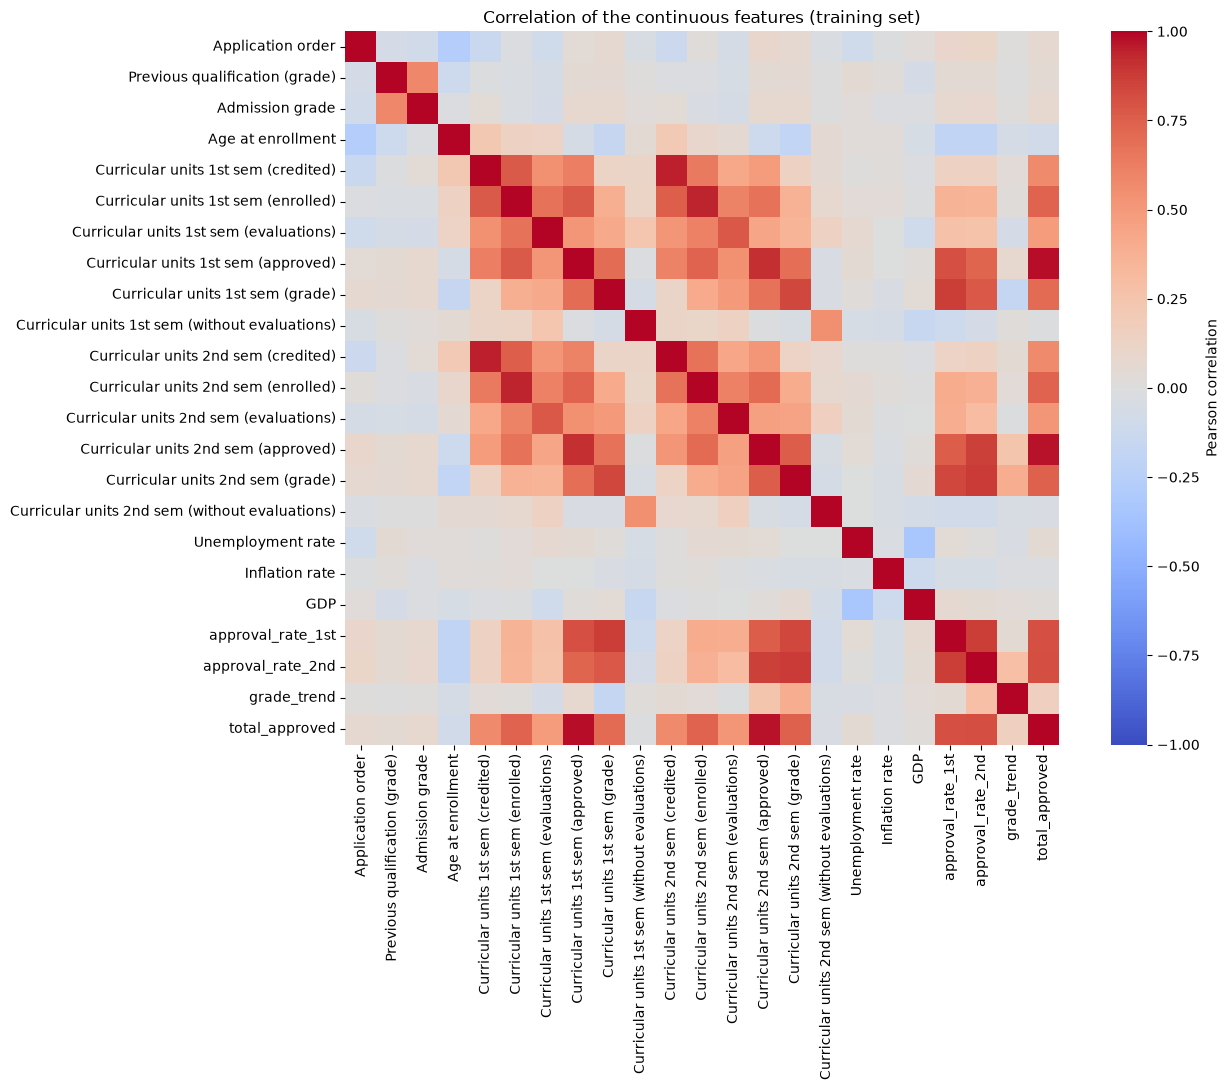

pairs with |r| > 0.7: 29


,,r
Curricular units 1st sem (approved),total_approved,0.977
Curricular units 2nd sem (approved),total_approved,0.976
Curricular units 1st sem (credited),Curricular units 2nd sem (credited),0.948
Curricular units 1st sem (enrolled),Curricular units 2nd sem (enrolled),0.943
Curricular units 1st sem (approved),Curricular units 2nd sem (approved),0.907
Curricular units 2nd sem (grade),approval_rate_2nd,0.881
approval_rate_1st,approval_rate_2nd,0.874
Curricular units 1st sem (grade),approval_rate_1st,0.869
Curricular units 2nd sem (approved),approval_rate_2nd,0.867
Curricular units 1st sem (grade),Curricular units 2nd sem (grade),0.839


In [11]:
import seaborn as sns

corr = X_train[CONTINUOUS_ALL].corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True,
            cbar_kws={"label": "Pearson correlation"})
plt.title("Correlation of the continuous features (training set)")
plt.tight_layout()
plt.show()

# each strongly correlated pair once, strongest first
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
strong = upper[upper.abs() > 0.7].sort_values(key=abs, ascending=False)
print(f"pairs with |r| > 0.7: {len(strong)}")
strong.round(3).rename("r").to_frame()

In [12]:
from sklearn.feature_selection import chi2, mutual_info_classif

M_train = prep.transform(X_train)
f_scores, _ = f_classif(M_train, y_train)
mi_scores = mutual_info_classif(M_train, y_train, random_state=RANDOM_STATE)

screening = pd.DataFrame({"anova_f": f_scores.round(2), "mutual_info": mi_scores.round(4)},
                         index=feature_names)
screening["anova_rank"] = screening["anova_f"].rank(ascending=False).astype(int)
screening["mi_rank"] = screening["mutual_info"].rank(ascending=False).astype(int)
screening["mean_rank"] = (screening[["anova_rank", "mi_rank"]].mean(axis=1)).round(1)

# chi-square needs non-negative input: the encoded columns and the binary flags
categorical = slice(0, n_nominal + len(BINARY))
chi_scores, chi_p = chi2(M_train[:, categorical], y_train)
print(f"chi-square: {(chi_p < 0.05).sum()} of {len(chi_p)} categorical columns significant at p < 0.05\n")

print("top 15 features by average rank:")
screening.sort_values("mean_rank").head(15)

chi-square: 48 of 86 categorical columns significant at p < 0.05

top 15 features by average rank:


,anova_f,mutual_info,anova_rank,mi_rank,mean_rank
approval_rate_2nd,1705.34,0.3450,1,1,1.0
Curricular units 2nd sem (approved),1092.91,0.3141,3,2,2.5
approval_rate_1st,1135.22,0.2757,2,4,3.0
total_approved,910.34,0.3119,5,3,4.0
Curricular units 2nd sem (grade),911.94,0.2382,4,5,4.5
Curricular units 1st sem (approved),660.29,0.2351,6,6,6.0
Curricular units 1st sem (grade),573.05,0.1769,7,7,7.0
Tuition fees up to date,406.06,0.0997,8,9,8.5
Scholarship holder,176.60,0.0554,9,13,11.0
Age at enrollment,124.84,0.0650,10,12,11.0


### 3.9 Dimensionality reduction with PCA · *Kusal*

PCA replaces correlated columns with uncorrelated combinations ordered by how much variance
each explains. It is applied to the scaled continuous columns only: rotating one-hot columns
would mix unrelated categories into components nobody could interpret. The component count
is chosen here from the training rows; inside the models, PCA sits in the pipeline and is
re-fitted on every training fold.

components for 80% of the variance: 8
components for 90% of the variance: 11
components for 95% of the variance: 13
components for 99% of the variance: 17

chosen: 13 components of 23 continuous columns


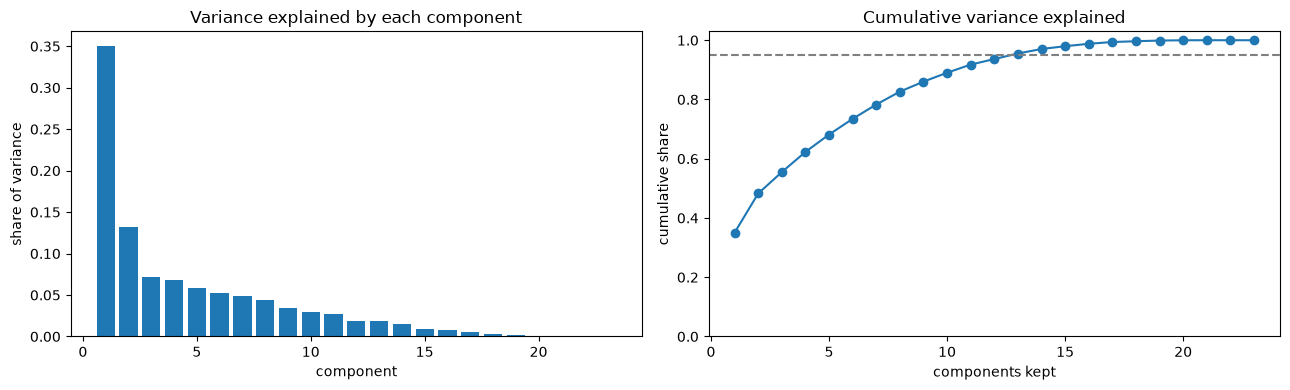

strongest loadings on the first component:


total_approved                         0.340
Curricular units 1st sem (approved)    0.336
Curricular units 2nd sem (approved)    0.327
Curricular units 1st sem (enrolled)    0.288
Curricular units 2nd sem (enrolled)    0.285
approval_rate_1st                      0.274
dtype: float64

In [13]:
pca_full = PCA(random_state=RANDOM_STATE).fit(train_scaled)
cumulative = pca_full.explained_variance_ratio_.cumsum()

for share in (0.80, 0.90, 0.95, 0.99):
    print(f"components for {share:.0%} of the variance: {int((cumulative < share).sum() + 1)}")
PCA_COMPONENTS = int((cumulative < 0.95).sum() + 1)
print(f"\nchosen: {PCA_COMPONENTS} components of {len(CONTINUOUS_ALL)} continuous columns")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
components = np.arange(1, len(cumulative) + 1)
axes[0].bar(components, pca_full.explained_variance_ratio_)
axes[0].set(title="Variance explained by each component", xlabel="component",
            ylabel="share of variance")
axes[1].plot(components, cumulative, marker="o")
axes[1].axhline(0.95, linestyle="--", color="grey")
axes[1].set(title="Cumulative variance explained", xlabel="components kept",
            ylabel="cumulative share", ylim=(0, 1.03))
plt.tight_layout()
plt.show()

loadings = pd.Series(pca_full.components_[0], index=CONTINUOUS_ALL)
print("strongest loadings on the first component:")
loadings.abs().sort_values(ascending=False).head(6).round(3)

### 3.10 The four feature variants the models use · *Lahiru, Kusal*

Both models are fitted to the same four variants, so the effect of the feature set can be
separated from the effect of the algorithm.

| variant | what it is | question it answers |
|---|---|---|
| `all` | every feature, encoded and scaled | the baseline set |
| `reduced` | the 40 strongest features by ANOVA F | does screening help, or just discard signal? |
| `pca` | continuous block replaced by its principal components | dimensionality reduction by extraction |
| `first_sem` | second-semester columns withheld | how early can a warning be issued? |

`first_sem` is about when data becomes available, not leakage: second-semester results are
the strongest predictors, but they do not exist until a student is most of a year in.

In [14]:
FIRST_SEM = [c for c in CONTINUOUS if "2nd sem" not in c] + ["approval_rate_1st"]


def build_pipeline(model, variant="all", k=40):
    """The preprocessing plus a model, for one of the four feature variants."""
    if variant == "first_sem":
        prep_step = build_preprocessor(continuous=FIRST_SEM)
    elif variant == "pca":
        prep_step = build_preprocessor(pca_components=PCA_COMPONENTS)
    else:
        prep_step = build_preprocessor()
    steps = [("prep", prep_step)]
    if variant == "reduced":
        steps.append(("select", SelectKBest(f_classif, k=k)))
    return Pipeline(steps + [("model", model)])


from sklearn.dummy import DummyClassifier

widths = {variant: build_pipeline(DummyClassifier(), variant).fit(X_train, y_train)[:-1]
          .transform(X_train).shape[1]
          for variant in ("all", "reduced", "pca", "first_sem")}
pd.Series(widths, name="features").to_frame()

,features
all,109
reduced,40
pca,99
first_sem,100


### 3.11 The baseline every model must beat · *Lahiru, Kusal*

As in Lab 03, a naive baseline comes first so later numbers mean something. A classifier that
always answers the most common class, `Graduate`, scores about 50% accuracy while identifying
no student at risk at all. That is why the models are judged on macro-F1, which counts the
three classes equally, rather than on accuracy.

In [15]:
baseline = cross_validate(DummyClassifier(strategy="most_frequent"), X_train, y_train,
                          cv=cv, scoring=["accuracy", "f1_macro"])
print(f"majority-class baseline (5-fold, training set): "
      f"accuracy {baseline['test_accuracy'].mean():.3f} | "
      f"macro-F1 {baseline['test_f1_macro'].mean():.3f}")

assert len(X_test) == 885, "the test set stays untouched until section 6"

majority-class baseline (5-fold, training set): accuracy 0.499 | macro-F1 0.222


### 3.12 Shared scoring · *Lahiru, Kusal*

Both models are scored by the same function, so their results tables have identical columns
and can be compared directly in section 6. Scores come from out-of-fold predictions: each
training row is predicted by a model fitted on the other four folds, so no row is scored by a
model that saw it. Macro-F1 leads, with balanced accuracy, MCC, ROC-AUC and the recall of each
class alongside it.

In [ ]:
from sklearn.metrics import average_precision_score, balanced_accuracy_score
from sklearn.model_selection import cross_val_predict

CLASSES = ["Dropout", "Enrolled", "Graduate"]


def cv_scores(pipeline, X, y, name, variant, binary=False):
    """Cross-validated scores from out-of-fold predictions, as one row of a results table."""
    proba = cross_val_predict(pipeline, X, y, cv=cv, method="predict_proba")
    if binary:
        predicted = (proba[:, 1] >= 0.5).astype(int)
    else:
        predicted = np.unique(y)[proba.argmax(axis=1)]

    row = {
        "model": name,
        "variant": variant,
        "accuracy": accuracy_score(y, predicted),
        "balanced_accuracy": balanced_accuracy_score(y, predicted),
        "f1_macro": f1_score(y, predicted, average="macro"),
        "mcc": matthews_corrcoef(y, predicted),
    }
    if binary:
        row["roc_auc"] = roc_auc_score(y, proba[:, 1])
        row["pr_auc"] = average_precision_score(y, proba[:, 1])
        row["recall_dropout"] = recall_score(y, predicted)
    else:
        row["roc_auc"] = roc_auc_score(y, proba, multi_class="ovr", labels=np.unique(y))
        per_class = recall_score(y, predicted, average=None, labels=CLASSES)
        row.update({f"recall_{c.lower()}": r for c, r in zip(CLASSES, per_class)})
    return row

## 4. Model 1 

## 5. Model 2

Model 2 is the Random Forest. It is tuned by cross-validation on the training set and run on
the four feature variants from section 3.10. The test set is not used here; every number in
this section is cross-validated on the 3,539 training rows, and the test set is opened once,
in section 6.

### 5.1 How a Random Forest works · *Kusal*

**A single decision tree** splits the data one feature at a time. At each node it searches
every feature and every threshold for the split that best separates the classes, measured by
the reduction in **Gini impurity**:

$$G = 1 - \sum_{k} p_k^2$$

where $p_k$ is the proportion of class $k$ at that node. A node containing only dropouts has
$G = 0$; one split evenly across all three outcomes has $G \approx 0.67$. The tree keeps
splitting until its leaves are pure or a stopping rule intervenes.

**The problem is variance.** Grown without limit, a tree isolates individual students, ending
with leaves that each hold one person, perfectly classified. Such a tree memorises the training
set and generalises badly, because the splits deep in the tree follow noise rather than
anything repeatable. Section 5.2 measures this directly.

**Bagging** addresses it by averaging. Many bootstrap samples are drawn, each the same size as
the training set and sampled with replacement, so roughly 37% of rows are left out of each. A
tree is fitted to each sample and the trees vote. Individual trees still overfit their own
sample, but their errors are partly independent, so averaging cancels some of them.

**Random Forest adds a second source of randomness.** At each split, a tree may only consider a
random subset of features. Without this, every tree would pick the same dominant feature at
the root (here almost certainly a second-semester approval column), and the trees would be
highly correlated, which limits how much averaging can help.

### 5.2 Why not a single tree · *Kusal*

The claim that one tree overfits is easy to check: fit an unrestricted tree and compare its
training accuracy with its cross-validated accuracy, then do the same for a forest.

In [ ]:
tree = build_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE), variant="all")
tree.fit(X_train, y_train)
tree_train = tree.score(X_train, y_train)
tree_cv = cross_val_score(tree, X_train, y_train, cv=cv, scoring="accuracy").mean()

# same data and pipeline, 300 trees instead of one
forest = build_pipeline(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE,
                                               n_jobs=-1), variant="all")
forest.fit(X_train, y_train)
forest_train = forest.score(X_train, y_train)
forest_cv = cross_val_score(forest, X_train, y_train, cv=cv, scoring="accuracy").mean()

print(f"unrestricted tree: {tree.named_steps['model'].get_n_leaves()} leaves, "
      f"depth {tree.named_steps['model'].get_depth()}")
comparison = pd.DataFrame({
    "training accuracy": [tree_train, forest_train],
    "cross-validated accuracy": [tree_cv, forest_cv],
}, index=["single tree", "random forest (300)"])
comparison["overfitting gap"] = comparison["training accuracy"] - comparison["cross-validated accuracy"]
comparison.round(4)

Both reach near-perfect training accuracy, so neither is underfitting. The difference is what
happens on unseen rows: the forest's cross-validated accuracy is much higher while its
training accuracy is the same. That gap is variance, and averaging over 300 decorrelated trees
is what reduces it. The forest still overfits, only less.

#### 5.2.1 Can a single tree be controlled instead?

Nobody would deploy an unrestricted tree, so the fair question is whether a pruned one closes
the gap. Limiting `max_depth` is the standard way to stop a tree memorising its training rows.
The sweep below fits one tree per depth, and then compares the two split criteria from Lab 06,
Gini and entropy, at the best depth.

In [ ]:
rows = []
for depth in [2, 3, 4, 5, 6, 8, 10, 15, None]:
    pruned = build_pipeline(DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE))
    scores = cross_validate(pruned, X_train, y_train, cv=cv,
                            scoring=["accuracy", "f1_macro"], return_train_score=True)
    rows.append({
        "max_depth": "None" if depth is None else depth,
        "train accuracy": scores["train_accuracy"].mean(),
        "cv accuracy": scores["test_accuracy"].mean(),
        "cv macro-F1": scores["test_f1_macro"].mean(),
    })

depth_sweep = pd.DataFrame(rows).set_index("max_depth")
depth_sweep["gap"] = depth_sweep["train accuracy"] - depth_sweep["cv accuracy"]
best_depth = depth_sweep["cv macro-F1"].idxmax()
print("best single-tree depth by cross-validated macro-F1:", best_depth)
depth_sweep.round(4)

In [ ]:
depth_value = None if best_depth == "None" else int(best_depth)
criteria = {}
for criterion in ["gini", "entropy"]:
    candidate = build_pipeline(DecisionTreeClassifier(max_depth=depth_value, criterion=criterion,
                                                      random_state=RANDOM_STATE))
    s = cross_validate(candidate, X_train, y_train, cv=cv, scoring=["accuracy", "f1_macro"])
    criteria[criterion] = {"cv accuracy": s["test_accuracy"].mean(),
                           "cv macro-F1": s["test_f1_macro"].mean()}
pd.DataFrame(criteria).T.round(4)

#### 5.2.2 What the tree decides first

A depth-3 tree is small enough to read. Its root split is the single question that best
separates the outcomes. Continuous columns are standardised inside the pipeline, so the root
threshold is converted back to its original units; the rule list and the plot keep the
standardised values, in standard deviations from the mean.

In [ ]:
from sklearn.tree import export_text, plot_tree

small = build_pipeline(DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE))
small.fit(X_train, y_train)

tree_prep = small.named_steps["prep"]
tree_model = small.named_steps["model"]
tree_names = list(tree_prep.get_feature_names_out())
tree_scaler = tree_prep.named_transformers_["continuous"].named_steps["scale"]


def original_units(feature, threshold):
    # undo the standardisation so the rule reads in the column's own units
    if feature in CONTINUOUS_ALL:
        j = CONTINUOUS_ALL.index(feature)
        return threshold * tree_scaler.scale_[j] + tree_scaler.mean_[j]
    return threshold


root_feature = tree_names[tree_model.tree_.feature[0]]
print(f"root rule: {root_feature} <= "
      f"{original_units(root_feature, tree_model.tree_.threshold[0]):.3f}\n")
print(export_text(tree_model, feature_names=tree_names, max_depth=3))

fig, ax = plt.subplots(figsize=(18, 7.5))
plot_tree(tree_model, feature_names=tree_names, class_names=list(tree_model.classes_),
          filled=True, rounded=True, proportion=True, fontsize=8, ax=ax)
ax.set_title("Depth-3 decision tree (continuous thresholds in standard deviations)")
plt.tight_layout()
plt.show()

**Pruning helps a lot, but not enough.** Capping the tree at depth 4 cuts the overfitting gap
from about 0.32 to about 0.01 and lifts cross-validated accuracy from 0.68 to 0.75, but the
forest stays ahead. A shallow tree has too few questions to separate three overlapping
classes, and a deep tree overfits; the forest avoids the choice by growing deep trees and
averaging away their variance. Gini and entropy finish within a few thousandths of each other,
the usual result from Lab 06.

The root split is on `approval_rate_2nd`, at roughly 77% of second-semester units passed, the
feature ranked first by every test in section 3.8. Below it, `Tuition fees up to date` appears
in every branch. A student with a middling approval rate whose fees are paid lands in
`Enrolled`; the same student with unpaid fees lands in `Dropout`.

### 5.3 Why a Random Forest suits this dataset · *Kusal*

**The features are mixed in type and scale.** Trees split on one feature at a time, so they are
indifferent to `Age at enrollment` running 17 to 70 while `approval_rate_1st` runs 0 to 1.

**The relationships are not monotonic.** Section 3.8 found features that mutual information
ranks far higher than the ANOVA F-test, such as `grade_trend`, which points to relationships
that are not straight lines. A linear model needs manual interaction terms for these; a tree
captures them by construction.

**Interactions matter and are not known in advance.** Whether a low approval rate predicts
dropout plausibly depends on fees, course and attendance pattern, and a forest finds such
combinations without being told where to look.

**It gives a second, independent view of feature importance**, from inside a fitted model
rather than one feature at a time. Section 5.6 compares the two.

The counterweight is interpretability: a Logistic Regression coefficient states the direction
and size of an effect, and 300 trees do not.

### 5.4 Tuning · *Kusal*

`GridSearchCV` over the 5 stratified folds of the training set, scored on macro-F1 so that
`Enrolled`, the smallest and hardest class, counts as much as `Graduate`. Every trial is logged.
`class_weight` is part of the grid rather than fixed: `balanced` reweights classes by inverse
frequency, and `balanced_subsample` recomputes those weights for each bootstrap sample.

In [ ]:
grid = {
    "model__n_estimators": [300],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_leaf": [1, 2, 5],
    "model__max_features": ["sqrt", 0.3],
    "model__class_weight": [None, "balanced", "balanced_subsample"],
}
search = GridSearchCV(
    build_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1)),
    param_grid=grid, scoring="f1_macro", cv=cv, n_jobs=-1, refit=True,
)
search.fit(X_train, y_train)

print(f"combinations tried: {len(search.cv_results_['params'])}")
print(f"best macro-F1     : {search.best_score_:.4f}")
for key, value in sorted(search.best_params_.items()):
    print(f"  {key.replace('model__', ''):18s} {value}")

# trial log, best first
grid_results = pd.DataFrame(search.cv_results_)
log = grid_results[[c for c in grid_results.columns if c.startswith("param_model__")]
                   + ["mean_test_score", "std_test_score"]]
log.columns = [c.replace("param_model__", "") for c in log.columns]
log.sort_values("mean_test_score", ascending=False).round(4).reset_index(drop=True).head(10)

In [ ]:
# how much each parameter matters on its own; keys come from cv_results_["params"] because
# the param_ columns turn None into NaN, which groupby would drop silently
for parameter in ["model__max_depth", "model__min_samples_leaf",
                  "model__max_features", "model__class_weight"]:
    keys = [str(p[parameter]) for p in search.cv_results_["params"]]
    effect = (grid_results.assign(setting=keys).groupby("setting")["mean_test_score"]
              .agg(["mean", "max"]).round(4).sort_values("mean", ascending=False))
    print(f"{parameter.replace('model__', '')}:\n{effect.to_string()}\n")

Only `class_weight` makes a real difference. Depth, leaf size and feature-subset size each move
the mean score by a few thousandths, because averaging 300 trees already controls the variance
that limiting depth would control. The imbalance, not the capacity, was the thing worth tuning.

### 5.5 The four feature variants · *Kusal*

The tuned settings are reused on all four variants, so the only thing changing between rows is
the feature set.

In [ ]:
best = search.best_params_


def best_forest(**overrides):
    """The tuned forest, with named parameters overridden."""
    params = {key.replace("model__", ""): value for key, value in best.items()}
    params.update(random_state=RANDOM_STATE, n_jobs=-1, **overrides)
    return RandomForestClassifier(**params)


VARIANTS = {"all": "all features", "reduced": "reduced", "pca": "pca", "first_sem": "1st sem only"}
rf_results = pd.DataFrame([
    cv_scores(build_pipeline(best_forest(), variant), X_train, y_train,
              name="Random Forest", variant=label)
    for variant, label in VARIANTS.items()
])
rf_results.round(4)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(data=rf_results, x="variant", y="f1_macro", ax=axes[0])
axes[0].set(title="Macro-F1 by feature variant", xlabel="", ylim=(0, 1))

per_class = rf_results.melt(id_vars="variant",
                            value_vars=["recall_dropout", "recall_enrolled", "recall_graduate"],
                            var_name="class", value_name="recall")
per_class["class"] = per_class["class"].str.replace("recall_", "")
sns.barplot(data=per_class, x="class", y="recall", hue="variant", ax=axes[1])
axes[1].set(title="Recall by class and variant", xlabel="", ylim=(0, 1))
plt.tight_layout()
plt.show()

# out-of-fold confusion matrix for the all-features forest
predicted = cross_val_predict(build_pipeline(best_forest()), X_train, y_train, cv=cv)
matrix = pd.DataFrame(confusion_matrix(y_train, predicted, labels=CLASSES),
                      index=pd.Index(CLASSES, name="true"),
                      columns=pd.Index(CLASSES, name="predicted"))
print("row percentages:")
print((matrix.div(matrix.sum(axis=1), axis=0) * 100).round(1))
ConfusionMatrixDisplay(matrix.to_numpy(), display_labels=CLASSES).plot(cmap="Blues")
plt.title("Random Forest, out-of-fold confusion matrix")
plt.show()

Neither form of reduction helps: PCA and ANOVA selection each cost about a point of macro-F1.
PCA gives the best dropout recall of the four and the worst `Enrolled` recall, which is what an
unsupervised method that maximises variance without looking at the target would be expected to
do. In the confusion matrix, about a quarter of `Enrolled` students are predicted to graduate:
the model is systematically optimistic about the students who are behind schedule.

### 5.6 Which features the forest used · *Kusal*

`feature_importances_` is the total reduction in Gini impurity attributable to each feature,
averaged over the 300 trees. It favours features with many possible split points, such as
continuous columns and high-cardinality encodings, so the ranking is read as indicative and
checked against section 3.8 and the descriptor paper's five most important features.

In [ ]:
fitted = build_pipeline(best_forest()).fit(X_train, y_train)
importance = (pd.DataFrame({"feature": fitted.named_steps["prep"].get_feature_names_out(),
                            "importance": fitted.named_steps["model"].feature_importances_})
              .sort_values("importance", ascending=False).reset_index(drop=True))
importance["rank"] = importance.index + 1

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(data=importance.head(20), y="feature", x="importance", ax=ax)
ax.set(title="Random Forest feature importance, top 20", ylabel="")
plt.tight_layout()
plt.show()

paper_five = ["Curricular units 2nd sem (approved)", "Curricular units 1st sem (approved)",
              "Curricular units 2nd sem (grade)", "Course", "Tuition fees up to date"]
print("the paper's five features and the four engineered ones, as ranked by the forest:")
for name in paper_five + ENGINEERED:
    hit = importance[importance["feature"].str.startswith(name)].iloc[0]
    print(f"  {name:38s} rank {hit['rank']:3d}  importance {hit['importance']:.4f}")
print(f"\nfeatures with effectively zero importance: "
      f"{int((importance['importance'] < 0.0005).sum())} of {len(importance)}")

### 5.7 How early can a warning be issued? · *Kusal*

The `first_sem` variant withholds every second-semester column. Second-semester results are
the strongest predictors, but they do not exist until a student is most of a year in, so the
difference between the two rows below is what accuracy costs to act a semester sooner.

In [ ]:
early = rf_results.set_index("variant").loc[["all features", "1st sem only"],
        ["accuracy", "balanced_accuracy", "f1_macro", "mcc", "roc_auc",
         "recall_dropout", "recall_enrolled", "recall_graduate"]].T
early["change"] = early["1st sem only"] - early["all features"]
early.round(4)

Acting a semester earlier costs about 2.6 points of macro-F1, but only about 1.4 points of
dropout recall; most of the loss falls on `Enrolled`. The early model keeps nearly all of its
ability to do the job it exists for.

### 5.8 Binary framing: Dropout vs rest · *Kusal*

Collapsing the outcomes to Dropout against everything else matches how a student support office
would use the model, as a list of students to contact. The tuned forest is reused with its class
weights and scored on the binary task; average precision (PR-AUC) is the headline here because
Dropout is the minority class at 32.1%.

In [ ]:
yb_train = (y_train == "Dropout").astype(int)
rf_binary = cv_scores(build_pipeline(best_forest()), X_train, yb_train,
                      name="Random Forest", variant="all features", binary=True)
pd.Series({k: round(v, 4) if isinstance(v, float) else v for k, v in rf_binary.items()}).to_frame("Random Forest, Dropout vs rest")

### 5.9 Summary · *Kusal*

Everything in this section is cross-validated on the training set. The tuned settings and the
results table are kept for section 6, where the test set is used for the first time.

In [ ]:
print("Random Forest, 5-fold cross-validation on 3,539 training rows\n")
print(rf_results.set_index("variant")[["f1_macro", "balanced_accuracy", "mcc",
                                       "recall_dropout", "recall_enrolled"]]
      .sort_values("f1_macro", ascending=False).round(4).to_string())

rf_params = {key.replace("model__", ""): value for key, value in best.items()}
print("\ntuned Random Forest:", rf_params)

assert len(X_test) == 885, "the test set stays untouched until section 6"

## 6. Model Comparison & Evaluation